In [1]:
# This is a complete new dataset which i have downloaded from lila dataset 
# Exploring this one for testing purpose:--
import matplotlib.pyplot as plt
import cv2
print("cv2 imported successfully")
import os
# Raw path for dataset
data_raw_path = "D:\\Camera_trap\\data\\raw_data"

for root, dirs, files in os.walk(data_raw_path):
    level = root.replace(data_raw_path, "").count(os.sep)
    if level < 3:
        indent = ' ' * 2 * level
        print(f"{indent}{os.path.basename(root)}/")
        if level == 2:
            print(f"{indent}  ({len(files)} files)")
            

cv2 imported successfully
raw_data/
  eccv_18_all_images_sm/
  eccv_18_annotation_files/


In [2]:
# Hence we got the two folders inside the raw dataset folder 
# Now we need to explore those folders:--

base_path = "D:\\Camera_trap\\data\\raw_data"
for item in os.listdir(os.path.join(base_path, "eccv_18_all_images_sm")):
    print(item)

# All images gets printed after running this 


5858bf2b-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf2c-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf33-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf35-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf3a-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf4a-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf4d-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf51-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf5a-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf5d-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf67-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf6a-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf6d-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf6f-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf70-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf75-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf7c-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf86-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf8a-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf96-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf98-23d2-11e8-a6a3-ec086b02610b.jpg
5858bf9c-23d2-11e8-a6a3-ec086b02610b.jpg
5858bfa5-23d2-11e8-a6a3-ec086b02610b.jpg
5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg
5858bfad-23d2-11

In [3]:
# Checking the same for annotation folder:-
for item in os.listdir(os.path.join(base_path, "eccv_18_annotation_files" )):
    print(item)
    

caltech_bboxes_20200316.json
cis_test_annotations.json
cis_val_annotations.json
train_annotations.json
trans_test_annotations.json
trans_val_annotations.json


In [4]:
# Hence we got the 5 annotation files 
import json

# 1. test_annotations.json
annotation_test = "D:\\Camera_trap\\data\\raw_data\\eccv_18_annotation_files\\cis_test_annotations.json"
# Opening file :--
with open(annotation_test,"r") as f:
    data_json = json.load(f)

# Exploring keys inside test_annotation.json
for keys in data_json.keys():
    print(f"The keys in json files are {keys}")
# Counting each key value :--
for keys in data_json.keys():
    print(f"keys present in  {keys} have value {len(data_json[keys])}")

    
    
    




The keys in json files are info
The keys in json files are categories
The keys in json files are images
The keys in json files are annotations
keys present in  info have value 5
keys present in  categories have value 16
keys present in  images have value 15827
keys present in  annotations have value 16395


In [5]:
# Lets see animal catogories present inside data_set folder:--

# Identifying animal catogories:--

for category in data_json["categories"]:
    print(f"ID: {category['id']}  Name: {category['name']}")
    
# Used catogories inside json folder to fetch total types of animals:--



ID: 6  Name: bobcat
ID: 1  Name: opossum
ID: 30  Name: empty
ID: 9  Name: coyote
ID: 3  Name: raccoon
ID: 11  Name: bird
ID: 8  Name: dog
ID: 16  Name: cat
ID: 5  Name: squirrel
ID: 10  Name: rabbit
ID: 7  Name: skunk
ID: 99  Name: rodent
ID: 21  Name: badger
ID: 34  Name: deer
ID: 33  Name: car
ID: 51  Name: fox


In [6]:
# Hence we got the 16 animal catogories 
# Lets find out how many animal annotations per category 
from collections import Counter
total_category_count = Counter()

for annotation_catogory in data_json["annotations"]:
    total_category_count[annotation_catogory["category_id"]] = total_category_count[annotation_catogory["category_id"]]+1

# Counting catogories
for category in data_json["categories"]:
    total_count = total_category_count[category["id"]]
    print(f"  {category['name']}: {total_count}")
# After this we get total animal present in each catogory:--

  bobcat: 909
  opossum: 4535
  empty: 1180
  coyote: 1372
  raccoon: 1103
  bird: 865
  dog: 895
  cat: 1672
  squirrel: 666
  rabbit: 1807
  skunk: 194
  rodent: 236
  badger: 4
  deer: 164
  car: 791
  fox: 2


In [7]:
# Now we will take furthur only valid catogories for our furthur phase of development:--
catogories_final =[]


for category in data_json["categories"]:
    count = total_category_count[category["id"]]
    if count > 100 and category["name"] != "empty" and category["name"] != "car":
        catogories_final.append(category)
print(f"Catogories after filtering {len(catogories_final)}")


        

Catogories after filtering 12


In [8]:
# We got 12 catogories to go with lets see what we got:-
for category in catogories_final:
    print(f"{category['id']} : {category['name']}")
    

6 : bobcat
1 : opossum
9 : coyote
3 : raccoon
11 : bird
8 : dog
16 : cat
5 : squirrel
10 : rabbit
7 : skunk
99 : rodent
34 : deer


In [9]:
# We need to get bounding box to identify image :--
# we got the annotation file which we need to get bbox on image:--
path_bbox = "D:\\Camera_trap\\data\\raw_data\\eccv_18_annotation_files\\caltech_bboxes_20200316.json"

# Annotation file :-caltech_bboxes_20200316
with open (path_bbox) as f:
    data_bbox = json.load(f)
print(f"Bounding box annotation we have got : {len(data_bbox['annotations'])}")
# We got the number of annotations present in file 

Bounding box annotation we have got : 65112


In [10]:
# Lets se how annotation looks like :--
print(data_bbox['annotations'][2])

{'image_id': '593d68d7-23d2-11e8-a6a3-ec086b02610b', 'id': '2a54599e-cbf1-11e8-819c-970a9450cdbc', 'bbox': [1779.2, 407.04, 61.440000000000055, 84.48000000000002], 'category_id': 5}


In [11]:
# Bounding box image function 
# Bbox function :--

def images_with_boxes(image_id):
    # This will fetch the image through dataset:--
    info_img = ""
    for image in data_bbox["images"]:
        if image["id"] == image_id:
            info_img = image
            
    # This will get the annotation of that image:--
    # This will store the annotation of image 
    info_annotation = []
    for annotation in data_bbox["annotations"]:
        if annotation["image_id"] == image_id:
            info_annotation.append(annotation)
    # Create image path :--
    info_image_path = os.path.join("D:\\Camera_trap\\data\\raw_data\\eccv_18_all_images_sm", info_img["file_name"])
    print(info_image_path)

    # Read and change color 
    info_image_display = cv2.imread(info_image_path)
    info_image_display = cv2.cvtColor(info_image_display, cv2.COLOR_BGR2RGB)
    
    # Bounding boxes on image:--
    for annotation in info_annotation:
        bbox = annotation["bbox"]
        x, y, w, h = bbox
        x1 = int(x)
        y1 = int(y)
        x2 = int(x + w)
        y2 = int(y + h)
        cv2.rectangle(info_image_display, (x1, y1), (x2, y2), (255, 0, 0), 3)
        print(f"Annotations found: {len(info_annotation)}")

    plt.figure(figsize=(10, 6))
    plt.imshow(info_image_display)
    plt.axis("off")
    plt.title(info_img["file_name"])
    plt.show()
    

D:\Camera_trap\data\raw_data\eccv_18_all_images_sm\5998cfa4-23d2-11e8-a6a3-ec086b02610b.jpg
Annotations found: 1


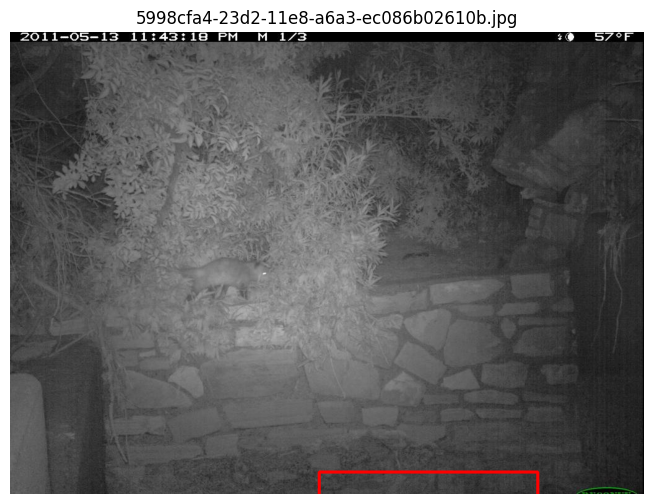

In [12]:
images_with_boxes("5998cfa4-23d2-11e8-a6a3-ec086b02610b")

In [13]:
# Getting image id for all images :--
image_id_box =[]

for annotation in data_bbox["annotations"]:
    id_image = annotation['image_id']
    if id_image + ".jpg" in downloaded_images:
        if id_image not in image_id_box :
            image_id_box.append(id_image)
print(f"Total id's are {len(image_id_box)}")
    

NameError: name 'downloaded_images' is not defined

In [ ]:
# Data exploration ends here 
# Findings which i got after this phase:--
# Total images on disk = 57864
# Images with bbox annotations = 44869
# Total bbox annotation = 65112
# Animal classes to undertake = 12

In [ ]:
# Exploring 13 classes which has to inside this folder 
import json

# Path to your original CCT20 annotation file with category names
with open(r"D:\Camera_trap\data\raw_data\eccv_18_annotation_files\cis_test_annotations.json") as f:
    original_data = json.load(f)

# Build a lookup: category_id -> real species name
id_to_name = {cat["id"]: cat["name"] for cat in original_data["categories"]}

print(id_to_name)